In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

try:
    import seaborn as sns
    HAS_SEABORN = True
    sns.set_theme(style="whitegrid")
except ImportError:
    HAS_SEABORN = False
    plt.style.use("seaborn-v0_8-whitegrid")

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

TOOL_ORDER = ["pandas", "polars", "dask"]
DATASET_ORDER = ["100k", "1m", "full"]
OPERATION_ORDER = ["read", "filter", "aggregation", "groupby"]

TOOL_COLORS = {"pandas": "#4C72B0", "polars": "#DD8452", "dask": "#55A868"}
DATASET_ROWS = {"100k": 100_000, "1m": 1_000_000, "full": 3_530_109}

In [2]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "results" / "processed"

SUMMARY_PATH = DATA_DIR / "benchmark_summary.csv"
MERGED_PATH = DATA_DIR / "merged_results.csv"
TOOL_VALIDATION_PATH = DATA_DIR / "tool_validation_report.csv"
CROSS_VALIDATION_PATH = DATA_DIR / "validation_report.csv"


def load_csv_or_fail(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Berkas tidak ditemukan: {path}")
    return pd.read_csv(path)


df_summary = load_csv_or_fail(SUMMARY_PATH)
df_merged = load_csv_or_fail(MERGED_PATH)
df_tool_validation = load_csv_or_fail(TOOL_VALIDATION_PATH)
df_cross_validation = load_csv_or_fail(CROSS_VALIDATION_PATH)

datasets = {
    "benchmark_summary.csv": df_summary,
    "merged_results.csv": df_merged,
    "tool_validation_report.csv": df_tool_validation,
    "validation_report.csv": df_cross_validation,
}

In [3]:
for name, df in datasets.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print("Dimensi:", df.shape)
    print(df.dtypes)
    display(df.head())
    print()

benchmark_summary.csv
Dimensi: (36, 13)
tool                          str
dataset                       str
dataset_size                int64
operation                     str
wall_time_seconds_mean    float64
cpu_time_seconds_mean     float64
memory_mb_mean            float64
wall_time_seconds_std     float64
cpu_time_seconds_std      float64
memory_mb_std             float64
repeat_count                int64
success_count               int64
failed_count                int64
dtype: object


,tool,dataset,dataset_size,operation,wall_time_seconds_mean,cpu_time_seconds_mean,memory_mb_mean,wall_time_seconds_std,cpu_time_seconds_std,memory_mb_std,repeat_count,success_count,failed_count
0,pandas,100k,100000,read,0.082288,0.175985,35.289844,0.073007,0.182427,38.761860,5,5,0
1,pandas,100k,100000,filter,0.067581,0.092192,16.435938,0.017853,0.032814,13.549247,5,5,0
2,pandas,100k,100000,aggregation,0.036701,0.052572,2.064844,0.001852,0.002048,2.452032,5,5,0
3,pandas,100k,100000,groupby,0.037222,0.054212,0.602344,0.002526,0.002595,1.278151,5,5,0
4,pandas,1m,1000000,read,0.652417,1.119203,121.590625,0.240631,0.396658,123.068488,5,5,0



merged_results.csv
Dimensi: (180, 13)
tool                     str
dataset                  str
dataset_size           int64
operation                str
repeat                 int64
wall_time_seconds    float64
cpu_time_seconds     float64
memory_mb            float64
memory_metric            str
result_rows          float64
result_sum           float64
result_groups        float64
validation_status        str
dtype: object


,tool,dataset,dataset_size,operation,repeat,wall_time_seconds,cpu_time_seconds,memory_mb,memory_metric,result_rows,result_sum,result_groups,validation_status
0,pandas,100k,100000,read,1,0.210496,0.501887,104.128906,sampled_peak_rss_delta,100000.0,NaN,NaN,passed
1,pandas,100k,100000,read,2,0.074059,0.108286,25.988281,sampled_peak_rss_delta,100000.0,NaN,NaN,passed
2,pandas,100k,100000,read,3,0.039600,0.085049,14.031250,sampled_peak_rss_delta,100000.0,NaN,NaN,passed
3,pandas,100k,100000,read,4,0.045358,0.098004,16.265625,sampled_peak_rss_delta,100000.0,NaN,NaN,passed
4,pandas,100k,100000,read,5,0.041927,0.086697,16.035156,sampled_peak_rss_delta,100000.0,NaN,NaN,passed



tool_validation_report.csv
Dimensi: (3, 9)
tool                          str
total_records               int64
expected_records            int64
failed_records              int64
missing_experiments         int64
unexpected_experiments      int64
duplicate_rows              int64
status                        str
issues                    float64
dtype: object


,tool,total_records,expected_records,failed_records,missing_experiments,unexpected_experiments,duplicate_rows,status,issues
0,pandas,60,60,0,0,0,0,success,NaN
1,polars,60,60,0,0,0,0,success,NaN
2,dask,60,60,0,0,0,0,success,NaN



validation_report.csv
Dimensi: (60, 6)
dataset              str
operation            str
repeat             int64
tools_present      int64
status               str
details          float64
dtype: object


,dataset,operation,repeat,tools_present,status,details
0,100k,aggregation,1,3,success,NaN
1,100k,aggregation,2,3,success,NaN
2,100k,aggregation,3,3,success,NaN
3,100k,aggregation,4,3,success,NaN
4,100k,aggregation,5,3,success,NaN


In [4]:
missing_summary = pd.DataFrame({
    name: df.isnull().sum() for name, df in datasets.items()
}).fillna(0).astype(int)
print("Jumlah nilai kosong per kolom per berkas:")
display(missing_summary.loc[(missing_summary != 0).any(axis=1)] if (missing_summary != 0).any().any()
        else missing_summary)

Jumlah nilai kosong per kolom per berkas:


,benchmark_summary.csv,merged_results.csv,tool_validation_report.csv,validation_report.csv
details,0,0,0,60
issues,0,0,3,0
result_groups,0,135,0,0
result_rows,0,60,0,0
result_sum,0,90,0,0


In [5]:
tool_status = df_tool_validation.set_index("tool")[
    ["total_records", "expected_records", "failed_records",
     "missing_experiments", "unexpected_experiments", "duplicate_rows", "status"]
]
print("Status validasi per tool:")
display(tool_status)

all_tools_success = (df_tool_validation["status"] == "success").all()
print(f"\nSemua tool lolos validasi individual: {all_tools_success}")

Status validasi per tool:


,total_records,expected_records,failed_records,missing_experiments,unexpected_experiments,duplicate_rows,status
tool,,,,,,,
pandas,60,60,0,0,0,0,success
polars,60,60,0,0,0,0,success
dask,60,60,0,0,0,0,success



Semua tool lolos validasi individual: True


In [6]:
cross_status_counts = df_cross_validation["status"].value_counts()
print("Distribusi status kesetaraan hasil antar-tools (per kombinasi dataset x operation x repeat):")
print(cross_status_counts)

failed_cross = df_cross_validation[df_cross_validation["status"] != "success"]
print(f"\nJumlah kombinasi gagal kesetaraan hasil: {len(failed_cross)}")
if len(failed_cross) > 0:
    display(failed_cross)

by_operation_status = (
    df_cross_validation
    .assign(is_success=lambda d: d["status"] == "success")
    .groupby("operation")["is_success"]
    .mean()
    .mul(100)
    .rename("persen_sukses")
)
print("\nPersentase kesetaraan hasil per jenis operasi:")
display(by_operation_status)

Distribusi status kesetaraan hasil antar-tools (per kombinasi dataset x operation x repeat):
status
success    60
Name: count, dtype: int64

Jumlah kombinasi gagal kesetaraan hasil: 0

Persentase kesetaraan hasil per jenis operasi:


operation
aggregation    100.0
filter         100.0
groupby        100.0
read           100.0
Name: persen_sukses, dtype: float64

In [7]:
metric_by_operation = {
    "read": ["result_rows"],
    "filter": ["result_rows"],
    "aggregation": ["result_sum"],
    "groupby": ["result_groups", "result_sum"],
}

consistency_records = []
for (dataset, operation), group in df_merged.groupby(["dataset", "operation"]):
    for metric in metric_by_operation[operation]:
        pivot = group.pivot_table(index="repeat", columns="tool", values=metric, aggfunc="first")
        n_unique_per_repeat = pivot.apply(lambda row: row.dropna().round(6).nunique(), axis=1)
        consistency_records.append({
            "dataset": dataset,
            "operation": operation,
            "metric": metric,
            "konsisten_semua_repeat": bool((n_unique_per_repeat <= 1).all()),
        })

df_consistency = pd.DataFrame(consistency_records).sort_values(["operation", "dataset", "metric"])
print("Konsistensi nilai hasil (result_rows / result_sum / result_groups) antar tools, per repeat:")
display(df_consistency)

Konsistensi nilai hasil (result_rows / result_sum / result_groups) antar tools, per repeat:


,dataset,operation,metric,konsisten_semua_repeat
0,100k,aggregation,result_sum,True
5,1m,aggregation,result_sum,True
10,full,aggregation,result_sum,True
1,100k,filter,result_rows,True
6,1m,filter,result_rows,True
11,full,filter,result_rows,True
2,100k,groupby,result_groups,True
3,100k,groupby,result_sum,True
7,1m,groupby,result_groups,True
8,1m,groupby,result_sum,True


In [8]:
def typed_categorical(df):
    out = df.copy()
    out["dataset"] = pd.Categorical(out["dataset"], categories=DATASET_ORDER, ordered=True)
    out["tool"] = pd.Categorical(out["tool"], categories=TOOL_ORDER, ordered=True)
    if "operation" in out.columns:
        out["operation"] = pd.Categorical(out["operation"], categories=OPERATION_ORDER, ordered=True)
    return out


summary = typed_categorical(df_summary).sort_values(["operation", "dataset", "tool"])
merged = typed_categorical(df_merged).sort_values(["operation", "dataset", "tool", "repeat"])

In [9]:
def grouped_bar(ax, data, x_col, hue_col, y_col, err_col, order, hue_order,
                 title, ylabel, colors=TOOL_COLORS):
    n_hue = len(hue_order)
    width = 0.8 / n_hue
    x_positions = np.arange(len(order))

    for i, hue in enumerate(hue_order):
        sub = data[data[hue_col] == hue].set_index(x_col).reindex(order)
        offset = (i - (n_hue - 1) / 2) * width
        ax.bar(x_positions + offset, sub[y_col], width=width,
               yerr=sub[err_col] if err_col in sub else None,
               capsize=3, label=hue, color=colors.get(hue))

    ax.set_xticks(x_positions)
    ax.set_xticklabels(order)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend(title=hue_col)
    return ax

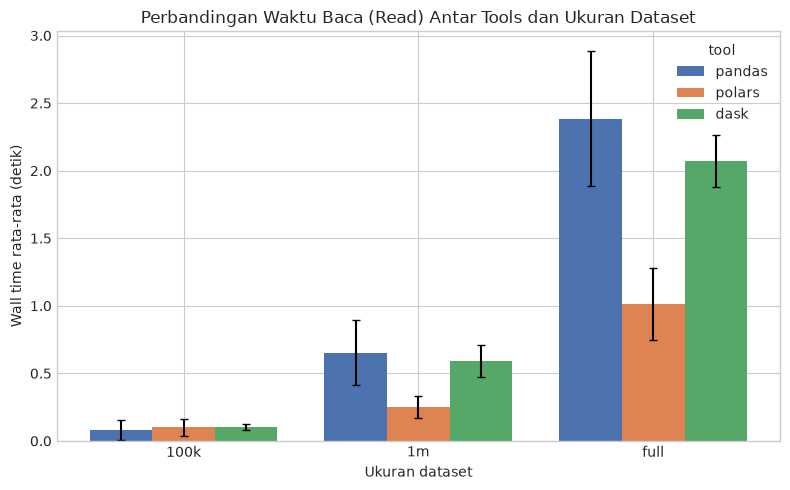

In [10]:
read_data = summary[summary["operation"] == "read"]

fig, ax = plt.subplots(figsize=(8, 5))
grouped_bar(ax, read_data, x_col="dataset", hue_col="tool", y_col="wall_time_seconds_mean",
            err_col="wall_time_seconds_std", order=DATASET_ORDER, hue_order=TOOL_ORDER,
            title="Perbandingan Waktu Baca (Read) Antar Tools dan Ukuran Dataset",
            ylabel="Wall time rata-rata (detik)")
ax.set_xlabel("Ukuran dataset")
plt.tight_layout()
plt.show()

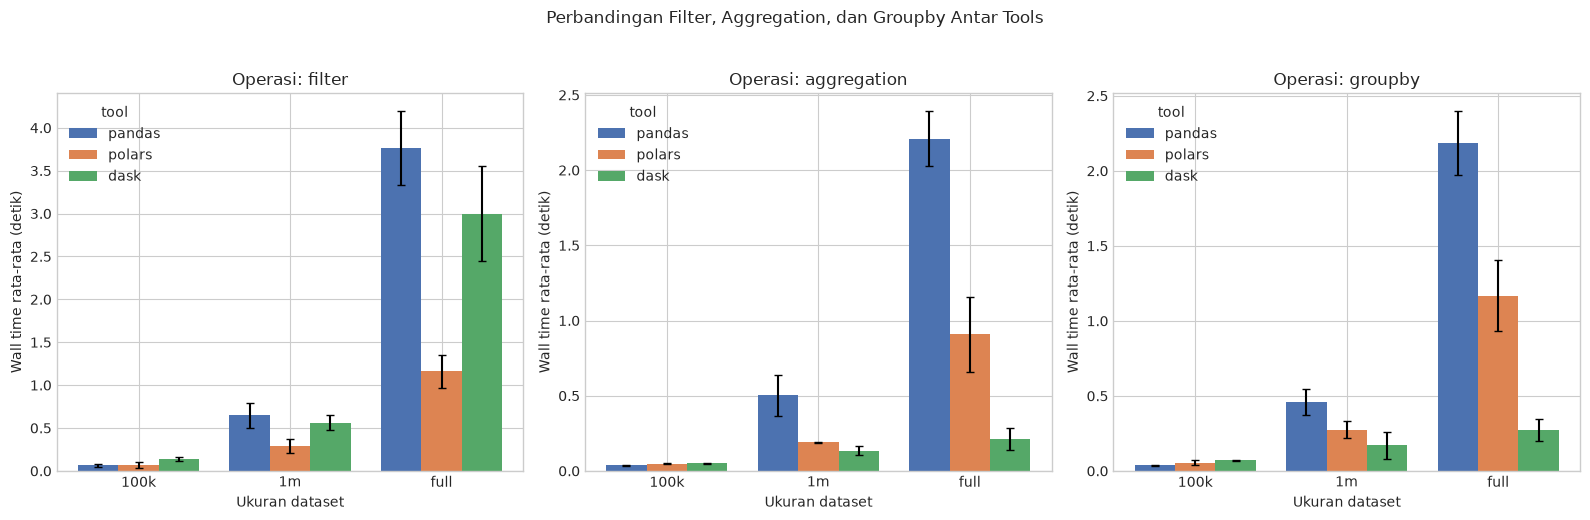

In [11]:
fast_ops = ["filter", "aggregation", "groupby"]

fig, axes = plt.subplots(1, len(fast_ops), figsize=(16, 5), sharey=False)
for ax, op in zip(axes, fast_ops):
    op_data = summary[summary["operation"] == op]
    grouped_bar(ax, op_data, x_col="dataset", hue_col="tool", y_col="wall_time_seconds_mean",
                err_col="wall_time_seconds_std", order=DATASET_ORDER, hue_order=TOOL_ORDER,
                title=f"Operasi: {op}", ylabel="Wall time rata-rata (detik)")
    ax.set_xlabel("Ukuran dataset")

plt.suptitle("Perbandingan Filter, Aggregation, dan Groupby Antar Tools", y=1.03)
plt.tight_layout()
plt.show()

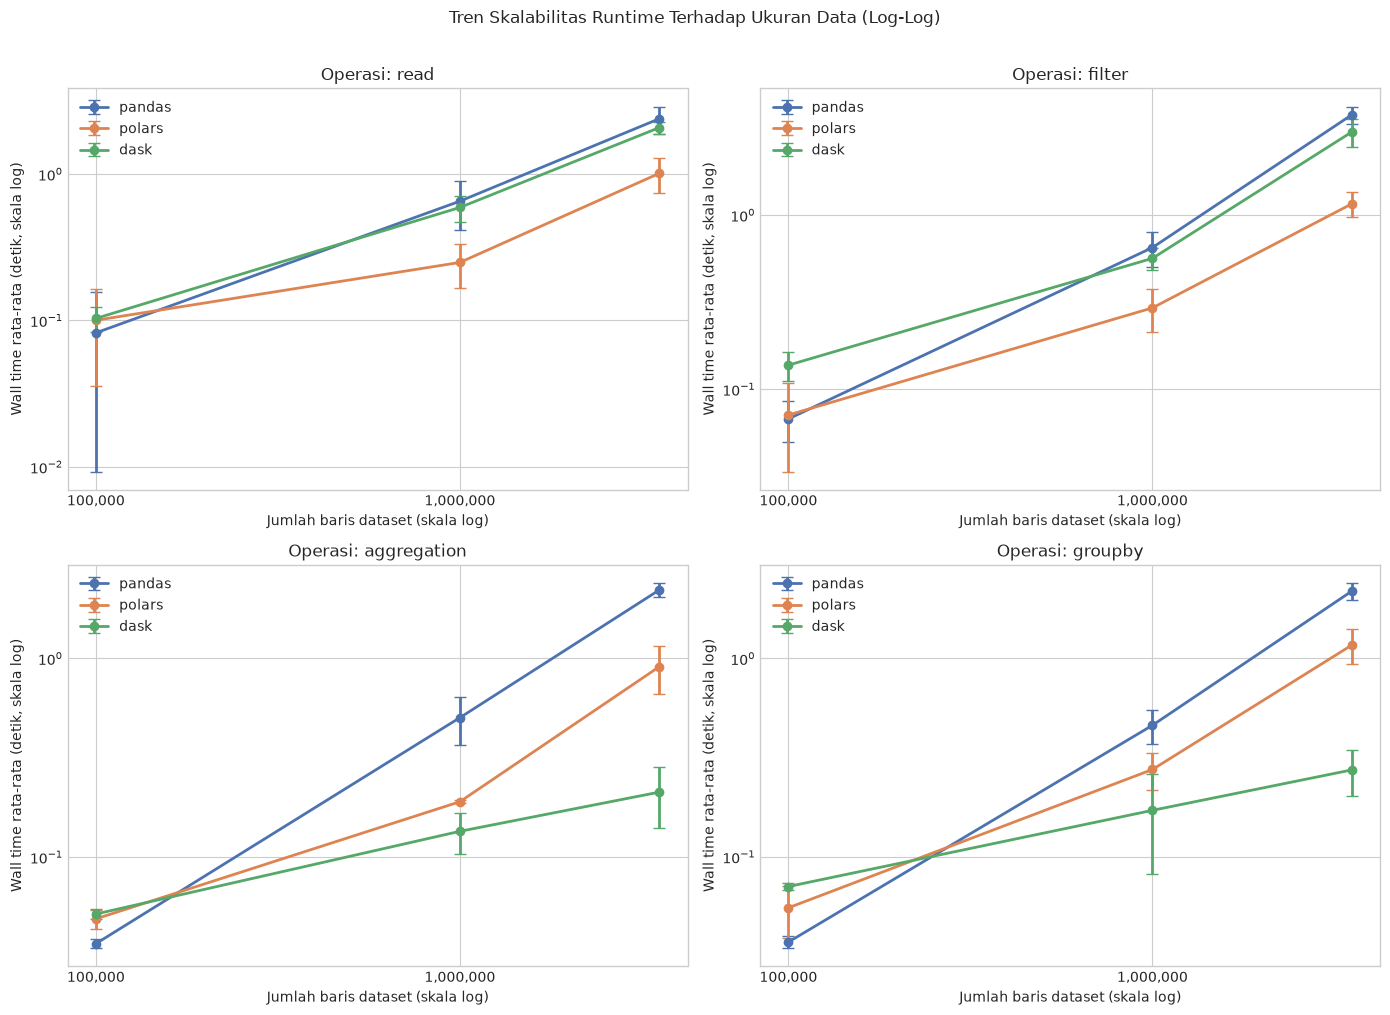

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, op in zip(axes, OPERATION_ORDER):
    op_data = summary[summary["operation"] == op]
    for tool in TOOL_ORDER:
        sub = op_data[op_data["tool"] == tool].sort_values("dataset_size")
        x = sub["dataset_size"].to_numpy()
        y = sub["wall_time_seconds_mean"].to_numpy()
        yerr = sub["wall_time_seconds_std"].to_numpy()
        ax.errorbar(x, y, yerr=yerr, marker="o", capsize=4, linewidth=2,
                    label=tool, color=TOOL_COLORS.get(tool))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"Operasi: {op}")
    ax.set_xlabel("Jumlah baris dataset (skala log)")
    ax.set_ylabel("Wall time rata-rata (detik, skala log)")
    ax.legend()
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))

plt.suptitle("Tren Skalabilitas Runtime Terhadap Ukuran Data (Log-Log)", y=1.01)
plt.tight_layout()
plt.show()

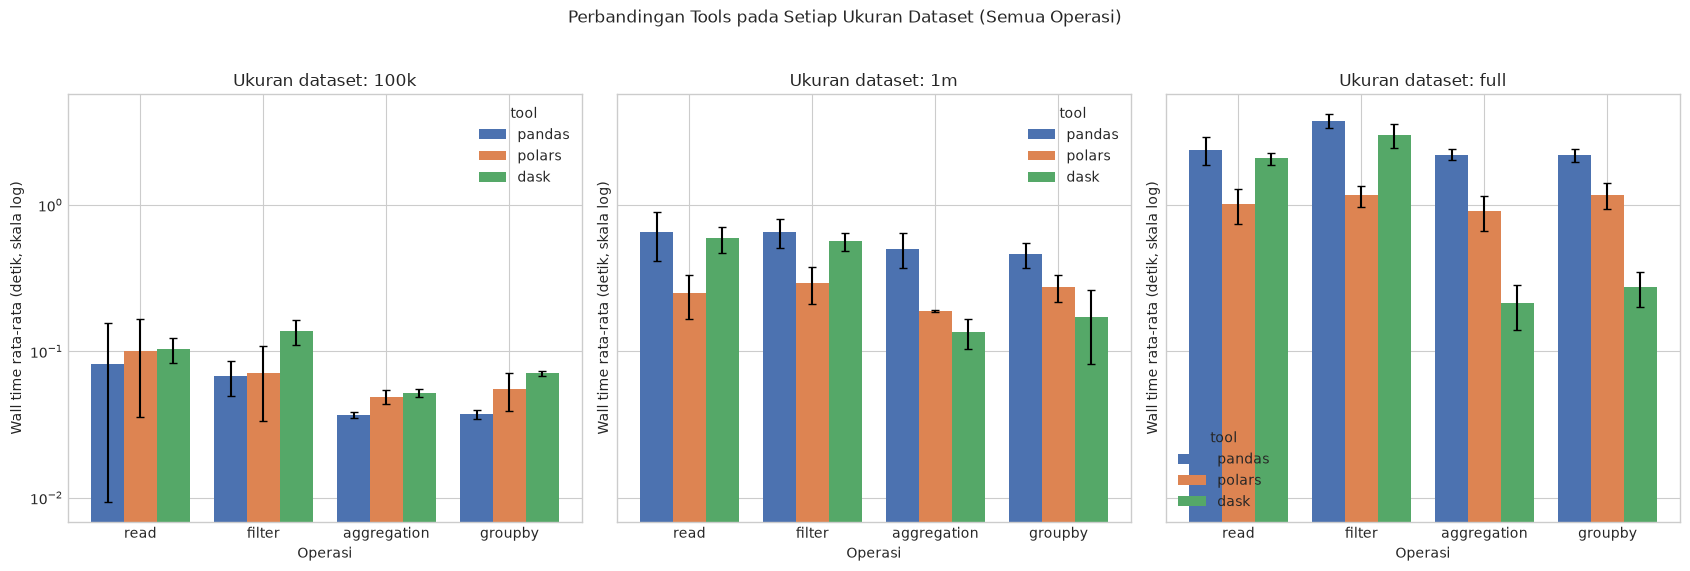

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)

for ax, dataset in zip(axes, DATASET_ORDER):
    size_data = summary[summary["dataset"] == dataset]
    grouped_bar(ax, size_data, x_col="operation", hue_col="tool", y_col="wall_time_seconds_mean",
                err_col="wall_time_seconds_std", order=OPERATION_ORDER, hue_order=TOOL_ORDER,
                title=f"Ukuran dataset: {dataset}", ylabel="Wall time rata-rata (detik, skala log)")
    ax.set_yscale("log")
    ax.set_xlabel("Operasi")

plt.suptitle("Perbandingan Tools pada Setiap Ukuran Dataset (Semua Operasi)", y=1.03)
plt.tight_layout()
plt.show()

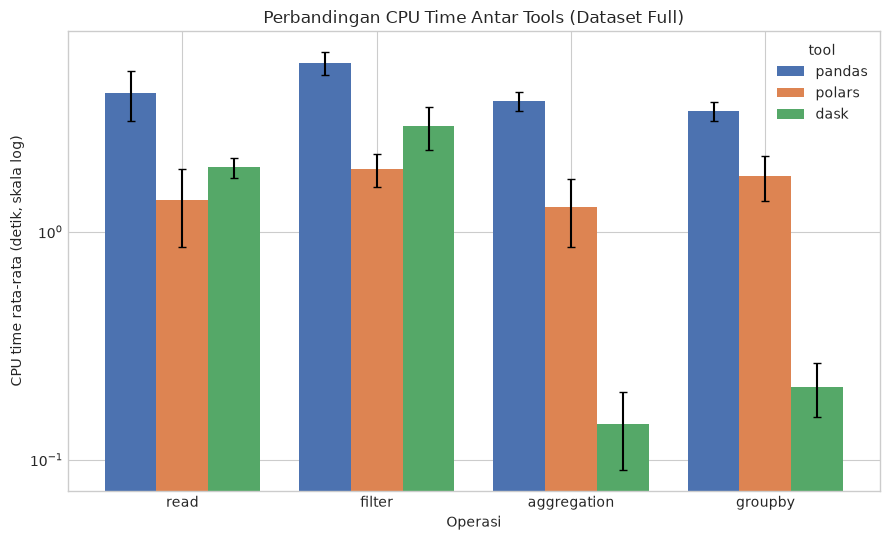

In [14]:
grouped_bar_data = summary[summary["dataset"] == "full"]

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, grouped_bar_data, x_col="operation", hue_col="tool", y_col="cpu_time_seconds_mean",
            err_col="cpu_time_seconds_std", order=OPERATION_ORDER, hue_order=TOOL_ORDER,
            title="Perbandingan CPU Time Antar Tools (Dataset Full)",
            ylabel="CPU time rata-rata (detik, skala log)")
ax.set_yscale("log")
ax.set_xlabel("Operasi")
plt.tight_layout()
plt.show()

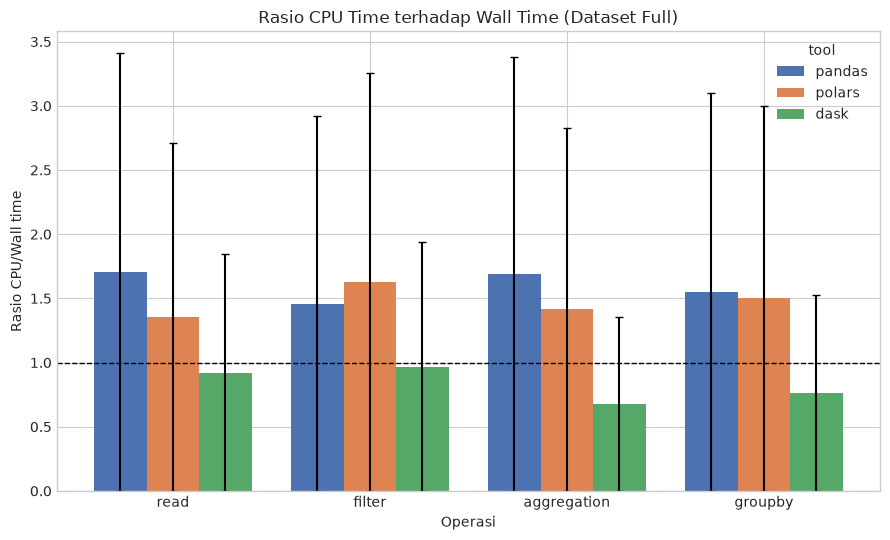

tool                   pandas    polars      dask
operation   dataset                              
read        100k     2.138644  0.680698  0.786730
            1m       1.715474  1.278193  0.823215
            full     1.704937  1.356867  0.921253
filter      100k     1.364158  0.790919  0.800074
            1m       1.440482  1.429185  0.833563
            full     1.459221  1.626376  0.968136
aggregation 100k     1.432468  0.541105  0.771283
            1m       1.467278  1.212464  0.723932
            full     1.691589  1.413392  0.676844
groupby     100k     1.456470  0.647698  0.853018
            1m       1.580727  1.326259  0.757501
            full     1.548738  1.499919  0.761759

In [15]:
efficiency = summary.copy()
efficiency["cpu_to_wall_ratio"] = efficiency["cpu_time_seconds_mean"] / efficiency["wall_time_seconds_mean"]

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, efficiency[efficiency["dataset"] == "full"], x_col="operation", hue_col="tool",
            y_col="cpu_to_wall_ratio", err_col="cpu_to_wall_ratio",
            order=OPERATION_ORDER, hue_order=TOOL_ORDER,
            title="Rasio CPU Time terhadap Wall Time (Dataset Full)",
            ylabel="Rasio CPU/Wall time")
ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Operasi")
plt.tight_layout()
plt.show()

display(efficiency.pivot_table(index=["operation", "dataset"], columns="tool",
                                 values="cpu_to_wall_ratio", observed=True))

Baris dikecualikan dari analisis memori karena memory_mb == 0: 49 dari 180


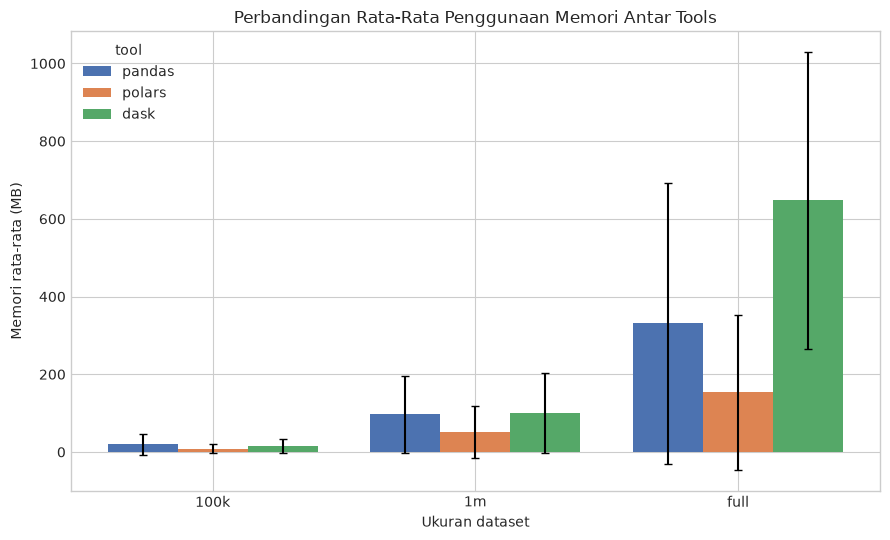

In [16]:
valid_memory = merged[merged["memory_mb"] > 0].copy()
n_excluded = len(merged) - len(valid_memory)
print(f"Baris dikecualikan dari analisis memori karena memory_mb == 0: {n_excluded} dari {len(merged)}")

memory_by_tool = (
    valid_memory.groupby(["tool", "dataset"], observed=True)["memory_mb"]
    .agg(mean="mean", std="std", n="count")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5.5))
grouped_bar(ax, memory_by_tool, x_col="dataset", hue_col="tool", y_col="mean", err_col="std",
            order=DATASET_ORDER, hue_order=TOOL_ORDER,
            title="Perbandingan Rata-Rata Penggunaan Memori Antar Tools",
            ylabel="Memori rata-rata (MB)")
ax.set_xlabel("Ukuran dataset")
plt.tight_layout()
plt.show()

In [17]:
cv_table = summary.copy()
cv_table["cv_wall_time_pct"] = (
    cv_table["wall_time_seconds_std"] / cv_table["wall_time_seconds_mean"] * 100
)

cv_pivot = cv_table.pivot_table(
    index=["operation", "dataset"], columns="tool", values="cv_wall_time_pct", observed=True
).loc[pd.MultiIndex.from_product([OPERATION_ORDER, DATASET_ORDER], names=["operation", "dataset"])]

print("Koefisien variasi wall time (%) per operasi, ukuran dataset, dan tool:")
display(cv_pivot.round(2))

most_variable = cv_table.loc[cv_table["cv_wall_time_pct"].idxmax()]
print(f"\nKombinasi dengan variabilitas tertinggi: {most_variable['tool']} / "
      f"{most_variable['operation']} / {most_variable['dataset']} "
      f"(CV = {most_variable['cv_wall_time_pct']:.1f}%)")

Koefisien variasi wall time (%) per operasi, ukuran dataset, dan tool:


tool                 pandas  polars   dask
operation   dataset                       
read        100k      88.72   64.50  19.70
            1m        36.88   32.84  19.98
            full      21.02   26.35   9.28
filter      100k      26.42   52.69  19.36
            1m        22.27   27.68  14.58
            full      11.42   16.24  18.50
aggregation 100k       5.05   10.95   6.12
            1m        26.84    1.60  23.14
            full       8.29   27.48  34.06
groupby     100k       6.79   29.39   3.73
            1m        19.06   20.77  52.43
            full       9.76   20.14  26.40


Kombinasi dengan variabilitas tertinggi: pandas / read / 100k (CV = 88.7%)


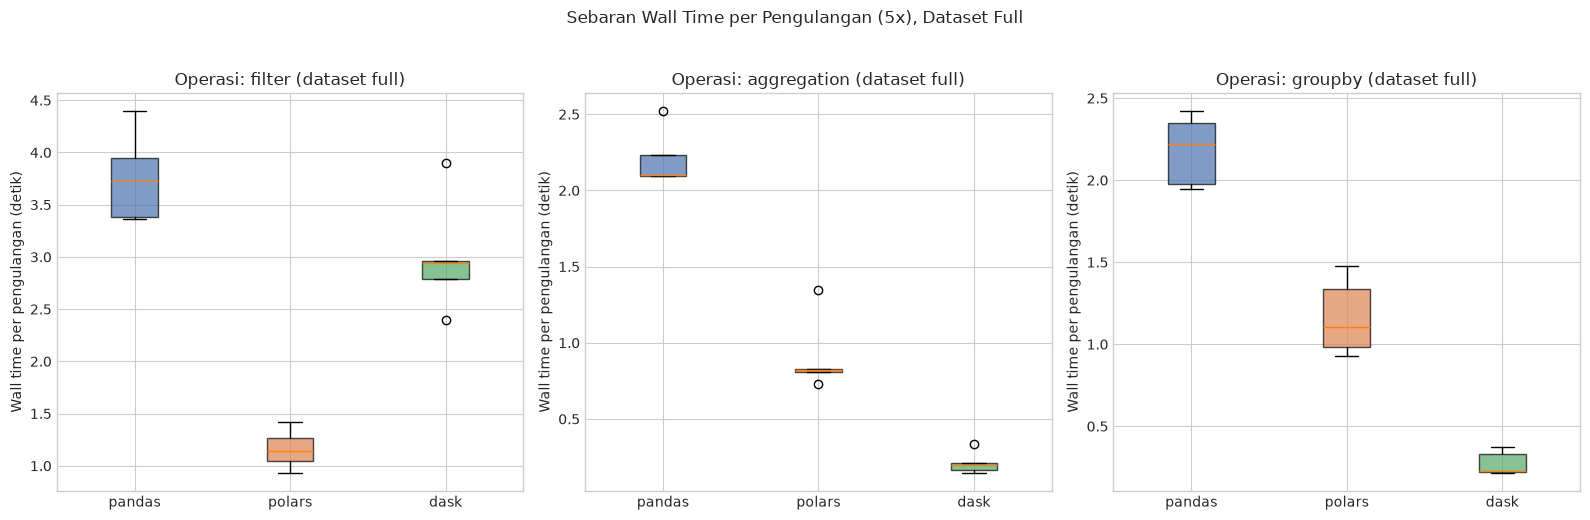

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, op in zip(axes, ["filter", "aggregation", "groupby"]):
    op_data = merged[merged["operation"] == op]
    box_data = [
        op_data[(op_data["tool"] == t) & (op_data["dataset"] == "full")]["wall_time_seconds"].values
        for t in TOOL_ORDER
    ]
    bp = ax.boxplot(box_data, patch_artist=True)
    ax.set_xticks(range(1, len(TOOL_ORDER) + 1))
    ax.set_xticklabels(TOOL_ORDER)
    for patch, tool in zip(bp["boxes"], TOOL_ORDER):
        patch.set_facecolor(TOOL_COLORS.get(tool))
        patch.set_alpha(0.7)
    ax.set_title(f"Operasi: {op} (dataset full)")
    ax.set_ylabel("Wall time per pengulangan (detik)")

plt.suptitle("Sebaran Wall Time per Pengulangan (5x), Dataset Full", y=1.03)
plt.tight_layout()
plt.show()

Speedup relatif terhadap Pandas (>1 berarti lebih cepat dari Pandas):


pandas_wall_time_s  polars_speedup_vs_pandas  dask_speedup_vs_pandas
operation   dataset                                                                      
read        100k                  0.082                     0.821                   0.797
            1m                    0.652                     2.620                   1.104
            full                  2.385                     2.360                   1.150
filter      100k                  0.068                     0.950                   0.491
            1m                    0.650                     2.219                   1.153
            full                  3.762                     3.245                   1.255
aggregation 100k                  0.037                     0.751                   0.710
            1m                    0.503                     2.648                   3.731
            full                  2.208                     2.432                  10.399
groupby     100k                  0.037                     0.672                   0.525
            1m                    0.460                     1.670                   2.682
            full                  2.183                     1.870                   7.960

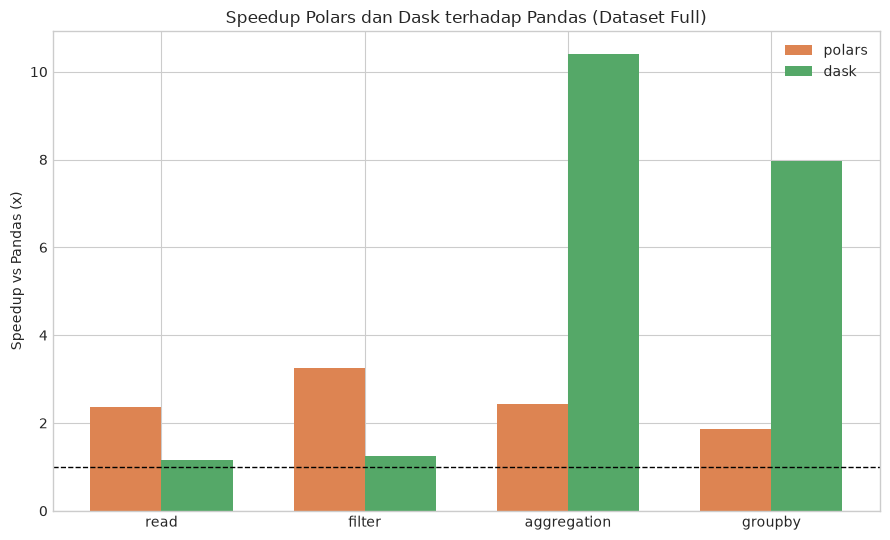

In [19]:
pivot_mean = summary.pivot_table(index=["operation", "dataset"], columns="tool",
                                   values="wall_time_seconds_mean", observed=True)
pivot_mean = pivot_mean.loc[pd.MultiIndex.from_product([OPERATION_ORDER, DATASET_ORDER],
                                                         names=["operation", "dataset"])]

speedup_table = pd.DataFrame(index=pivot_mean.index)
speedup_table["pandas_wall_time_s"] = pivot_mean["pandas"]
speedup_table["polars_speedup_vs_pandas"] = pivot_mean["pandas"] / pivot_mean["polars"]
speedup_table["dask_speedup_vs_pandas"] = pivot_mean["pandas"] / pivot_mean["dask"]

print("Speedup relatif terhadap Pandas (>1 berarti lebih cepat dari Pandas):")
display(speedup_table.round(3))

full_speedup = speedup_table.loc[(slice(None), "full"), ["polars_speedup_vs_pandas", "dask_speedup_vs_pandas"]]
full_speedup.index = full_speedup.index.get_level_values("operation")

fig, ax = plt.subplots(figsize=(9, 5.5))
x_positions = np.arange(len(full_speedup))
width = 0.35
ax.bar(x_positions - width / 2, full_speedup["polars_speedup_vs_pandas"], width=width,
       label="polars", color=TOOL_COLORS["polars"])
ax.bar(x_positions + width / 2, full_speedup["dask_speedup_vs_pandas"], width=width,
       label="dask", color=TOOL_COLORS["dask"])
ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_xticks(x_positions)
ax.set_xticklabels(full_speedup.index)
ax.set_ylabel("Speedup vs Pandas (x)")
ax.set_title("Speedup Polars dan Dask terhadap Pandas (Dataset Full)")
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
final_summary = summary.pivot_table(
    index=["operation", "dataset"],
    columns="tool",
    values=["wall_time_seconds_mean", "wall_time_seconds_std", "memory_mb_mean"],
    observed=True,
)
final_summary = final_summary.reorder_levels([0, 1], axis=1).sort_index(axis=1, level=0)
final_summary = final_summary.loc[
    pd.MultiIndex.from_product([OPERATION_ORDER, DATASET_ORDER], names=["operation", "dataset"])
]

print("Tabel ringkasan akhir: wall time (mean & std) dan memori (mean) per operasi, dataset, tool:")
display(final_summary.round(4))

Tabel ringkasan akhir: wall time (mean & std) dan memori (mean) per operasi, dataset, tool:


memory_mb_mean                     wall_time_seconds_mean                 wall_time_seconds_std  \
tool                        pandas    polars      dask                 pandas  polars    dask                pandas   
operation   dataset                                                                                                   
read        100k           35.2898   14.9500   20.2828                 0.0823  0.1003  0.1032                0.0730   
            1m            121.5906   79.6102  103.7055                 0.6524  0.2490  0.5910                0.2406   
            full          264.2086  232.2742  380.4805                 2.3855  1.0108  2.0749                0.5013   
filter      100k           16.4359   11.6414   13.1453                 0.0676  0.0712  0.1375                0.0179   
            1m            176.7109   57.0266   91.4359                 0.6504  0.2931  0.5642                0.1448   
            full          726.5281  168.4523  771.9672                 3.7625  1.1596  2.9989                0.4298   
aggregation 100k            2.0648    1.2422    0.0250                 0.0367  0.0489  0.0517                0.0019   
            1m             20.1445    2.1750    0.0250                 0.5032  0.1900  0.1349                0.1350   
            full           91.0875   25.2883    0.0000                 2.2081  0.9080  0.2123                0.1831   
groupby     100k            0.6023    1.5000    0.2000                 0.0372  0.0554  0.0709                0.0025   
            1m             10.6969   36.8156    5.5023                 0.4602  0.2756  0.1716                0.0877   
            full           42.7727  126.5875   12.9195                 2.1834  1.1673  0.2743                0.2131   

                                     
tool                 polars    dask  
operation   dataset                  
read        100k     0.0647  0.0203  
            1m       0.0818  0.1181  
            full     0.2663  0.1926  
filter      100k     0.0375  0.0266  
            1m       0.0811  0.0823  
            full     0.1883  0.5549  
aggregation 100k     0.0054  0.0032  
            1m       0.0030  0.0312  
            full     0.2496  0.0723  
groupby     100k     0.0163  0.0026  
            1m       0.0572  0.0900  
            full     0.2351  0.0724